# УИР 3. Исследование СМО и СеМО

Якименко Владислав Игоревич, P3313. Выборка УИР 1 — 16, СМО — вторая из УИР 2 (16/17/13), сетевая часть — 6/6.

**Цель работы (по методичке).** Исследование свойств систем и сетей массового обслуживания с однородным потоком заявок в среде имитационного моделирования GPSS при различных предположениях о параметрах структурно-функциональной организации и нагрузки в соответствии с формируемой исследователем (студентом) программой исследований.

**Среда моделирования.** Основные эксперименты выполнены в GPSS World Core. Модели прошли трансляцию, стандартные отчёты сохранены. Таблицы и графики ниже читаются из `results/gpss`; исходные проекты находятся в `gpss-native`. Python обрабатывает отчёты GPSS и выполняет независимый контроль.

Открой Notebook вместе с остальными файлами папки и выбери **Run All / Выполнить всё**. Обычный запуск пересчитывает контрольный опыт Python, читает результаты независимых повторений GPSS и заново строит графики. `python experiments.py` пересчитывает вспомогательную Python-модель; новые результаты GPSS получают запуском проектов в самой GPSS.

## 1. Подключение библиотек и исходных файлов
Первая ячейка обязательна. Если выполнить нижнюю ячейку раньше неё, имена `pd`, `np` и функции модели ещё не будут определены.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

candidates = [Path.cwd(), Path.cwd()/"Lab3", Path.cwd()/"Modeling"/"Lab3"]
ROOT = next((p for p in candidates if (p/"data"/"trace16.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Запусти Notebook из папки, где лежат model.py и data/trace16.csv")
sys.path.insert(0, str(ROOT))
from model import (smo, network, trace_parameters, confidence,
                   closed_exact, open_exact, VISITS, SERVERS, MEANS)
from markov_reference import solve, SYSTEMS
from plots import make_figures
from results_source import current_results
pd.options.display.float_format = "{:.6f}".format
RESULTS, NATIVE = current_results()
if not NATIVE:
    raise RuntimeError("Для итогового Notebook требуются проверенные результаты GPSS в results/gpss")
meta = json.loads((RESULTS/"metadata.json").read_text())
print("Python", sys.version.split()[0])
print("Числовой вариант — 16; сетевая модель — 6/6")

Python 3.12.14
Числовой вариант — 16; сетевая модель — 6/6


## 2. Выборка из УИР 1

Берём ровно 300 исходных значений варианта 16. Это интервалы между поступлениями. Из исходной Excel-таблицы использованы лист `1-50`, столбец с заголовком 16, строки 2–301.

$$a=\frac1N\sum_{i=1}^N X_i,\qquad
\widetilde D=\frac1{N-1}\sum_{i=1}^N(X_i-a)^2,\qquad
\widetilde\nu=\frac{\sqrt{\widetilde D}}a.$$

Для аппроксимации методом моментов используется дисперсия с делением на $N$ и коэффициент $\nu_a$. Различие с несмещённой оценкой явно сохранено.

In [2]:
x, a, nu_a, q, t1, t2 = trace_parameters()
assert len(x) == 300
assert (x > 0).all()
display(pd.Series({"N": len(x), "a, с": a,
    "Несмещённая дисперсия": x.var(ddof=1),
    "СКО — корень из исправленной дисперсии": x.std(ddof=1),
    "КВ по выборочному СКО": x.std(ddof=1)/a,
    "КВ для метода моментов": nu_a}))
display(pd.DataFrame({"Номер": np.arange(1,301), "Интервал, с": x}))

N                                        300.000000
a, с                                       8.020778
Несмещённая дисперсия                    510.430941
СКО — корень из исправленной дисперсии    22.592719
КВ по выборочному СКО                      2.816774
КВ для метода моментов                     2.812075
dtype: float64

,Номер,"Интервал, с"
0,1,5.618172
1,2,1.961323
2,3,0.958966
3,4,3.342269
4,5,3.238546
...,...,...
295,296,2.640204
296,297,2.510490
297,298,20.610528
298,299,3.981050


## 3. Три вида входного потока

Т — исходная трасса, повторяемая целиком в исходном порядке. А — гиперэкспоненциальная аппроксимация УИР 1. П — простейший поток с экспоненциальными интервалами. Среднее каждого закона равно $a$.

$$q=\frac12\left(1+\sqrt{\frac{\nu_a^2-1}{\nu_a^2+1}}\right),\qquad
t_1=\frac a{2q},\quad t_2=\frac a{2(1-q)}.$$

$$A_i=\begin{cases}-t_1\ln U_2,&U_1\le q,\\-t_2\ln U_2,&U_1>q.\end{cases}$$

У трассы нет новых независимых интервалов после первых 300. Независимые повторения этой серии меняют обслуживание и маршрутизацию. В GPSS перед новым повторением выполняется CLEAR, начальные числа генераторов задаются RMULT; RESET после разгона сбрасывает статистику и сохраняет состояние. Для случайных потоков равенство средних относится к закону, а не к каждой конечной реализации.

In [3]:
display(pd.Series({"q": q, "t1, с": t1, "t2, с": t2}))
np.testing.assert_allclose(q*t1 + (1-q)*t2, a)
np.testing.assert_allclose(2*(q*t1**2 + (1-q)*t2**2), np.mean(x*x))

q        0.940306
t1, с    4.264984
t2, с   67.182245
dtype: float64

## 4. СМО, выбранная в УИР 2

**Часть 1 «Исследование свойств систем массового обслуживания (СМО)».** Обозначения задания: $K$ — количество обслуживающих приборов; $E$ — ёмкость накопителя; $a$ — средний интервал между заявками; $b$ — средняя длительность обслуживания; КВ — коэффициент вариации длительности обслуживания. В формулах теоретического материала используется $\nu$; для входа, обслуживания, ожидания и пребывания — $\nu_a,\nu_b,\nu_w,\nu_u$.

Три направления с вероятностями $(0{,}30;0{,}45;0{,}25)$. В каждом — один прибор. Накопители имеют $E=(2,1,0)$ мест ожидания. П1 и П2 обслуживают экспоненциально, П3 — по Эрлангу второго порядка. Все средние обслуживания $b=5$ с. Для контроля сначала сохраняем $a=1{,}25$ с из УИР 2.

**Независимый контроль Python (`smo`).** Генерирует моменты поступления и выбор прибора. Удаляет из очереди событий завершившиеся заявки. Проверяет суммарную вместимость прибора и накопителя. Принятой заявке назначает начало и конец обслуживания. Отдельно собирает потери, времена и интегралы очередей. Это контрольный алгоритм; результаты основных опытов далее берутся из GPSS.

$$W_i=s_i-t_i,\qquad U_i=d_i-t_i=W_i+B_i,\qquad
\pi=\frac{N_{\text{пот}}}{N},\quad \lambda'=\frac{N-N_{\text{пот}}}{T}.$$

In [4]:
control = smo(n=100000, warmup=10000, a=1.25, b=5., seed=160600)
reference = solve(SYSTEMS[1])[-1]
keys = ["through", "pi", "w", "u", "l", "m"]
check = pd.DataFrame({"Марковский расчёт": {k:reference[k] for k in keys},
                      "Контрольный прогон Python": {k:control[k] for k in keys}})
check["Отклонение, %"] = abs(check.iloc[:,1]/check.iloc[:,0]-1)*100
display(check)

,Марковский расчёт,Контрольный прогон Python,"Отклонение, %"
through,0.429630,0.429188,0.102774
pi,0.462963,0.462180,0.169130
w,3.371498,3.379204,0.228561
u,8.371498,8.384031,0.149714
l,1.448495,1.450183,0.116543
m,3.596643,3.598207,0.043477


## 5. Сравнение с УИР 2 по 12 повторениям

Ниже результаты GPSS из 12 независимых повторений по 200 000 прошедших заявок (завершений обслуживания и отказов). Доверительный полуинтервал рассчитан по средним повторений, а не по зависимым ожиданиям отдельных заявок. Учтён допуск округления отчётов GPSS.

$$\overline z\pm\left(t_{0{,}975;R-1}\frac{s_z}{\sqrt R}+\Delta_{\rm окр}\right),\qquad
s_z^2=\frac{\sum_r(z_r-\overline z)^2}{R-1}.$$

In [5]:
baseline = pd.read_csv(RESULTS/"baseline.csv")
display(baseline)
replications = pd.read_csv(RESULTS/"baseline_replications.csv")
mean_w, halfwidth_w = confidence(replications.w)
halfwidth_w += .0005  # GPSS печатает среднее с тремя знаками после запятой.
print(f"Среднее ожидание: {mean_w:.6f} ± {halfwidth_w:.6f} с, доверие 0,95")
print("Максимальное отклонение от УИР 2, %:", baseline.error_percent.max())
assert len(baseline)==6 and np.isfinite(baseline.simulation).all()

,metric,markov,simulation,ci,error_percent
0,through,0.429630,0.430154,0.000513,0.121982
1,pi,0.462963,0.462458,0.000610,0.109100
2,w,3.371498,3.367083,0.012672,0.130945
3,u,8.371498,8.363083,0.017685,0.100517
4,l,1.448495,1.448417,0.006528,0.005434
5,m,3.596643,3.597500,0.010114,0.023818


Среднее ожидание: 3.367083 ± 0.012672 с, доверие 0,95
Максимальное отклонение от УИР 2, %: 0.1309451008314699


## 6. Программа исследования нагрузки и входа

Продолжаем на той же структуре и меняем $a$ на среднее УИР 1. Для согласованного сравнения используется максимальная **предлагаемая нагрузка**

$$y_j=\frac{\alpha_j b}{aK_j},\quad y_{\max}=\max_j y_j,\quad
b=\frac{y_{\max}a}{0{,}45}\quad(K_j=1).$$

Исследуем $0{,}5;0{,}75;0{,}95;0{,}99$. Фактическая загрузка измеряется отдельно и меньше из-за потерь. Эти числа не означают фактическую занятость приборов 95 или 99%. В `rho` таблицы СМО записана средняя занятость одного прибора, а в `rho1`, `rho2`, `rho3` — узловые значения.

,arrival,y,a,b,pi,pi_ci,w,w_ci,u,rho
0,M,0.500000,8.020778,8.911976,0.126921,0.001747,2.462875,0.027470,11.370375,0.323750
1,M,0.750000,8.020778,13.367964,0.203600,0.001808,5.116000,0.040897,18.466875,0.442500
2,M,0.950000,8.020778,16.932755,0.261825,0.001803,7.753375,0.077738,24.666625,0.519708
3,M,0.990000,8.020778,17.645713,0.273296,0.002474,8.274375,0.109717,25.897750,0.532958
4,T,0.500000,8.020778,8.911976,0.224627,0.001338,3.559750,0.042092,12.463250,0.286917
5,T,0.750000,8.020778,13.367964,0.316619,0.002158,6.638750,0.073545,19.983500,0.378958
6,T,0.950000,8.020778,16.932755,0.374106,0.001804,9.358125,0.066846,26.249625,0.439417
7,T,0.990000,8.020778,17.645713,0.385460,0.002868,9.940125,0.092034,27.535375,0.449292
8,A,0.500000,8.020778,8.911976,0.218085,0.001955,3.476625,0.027080,12.378500,0.287958
9,A,0.750000,8.020778,13.367964,0.315063,0.002280,6.629125,0.072988,19.973625,0.378250


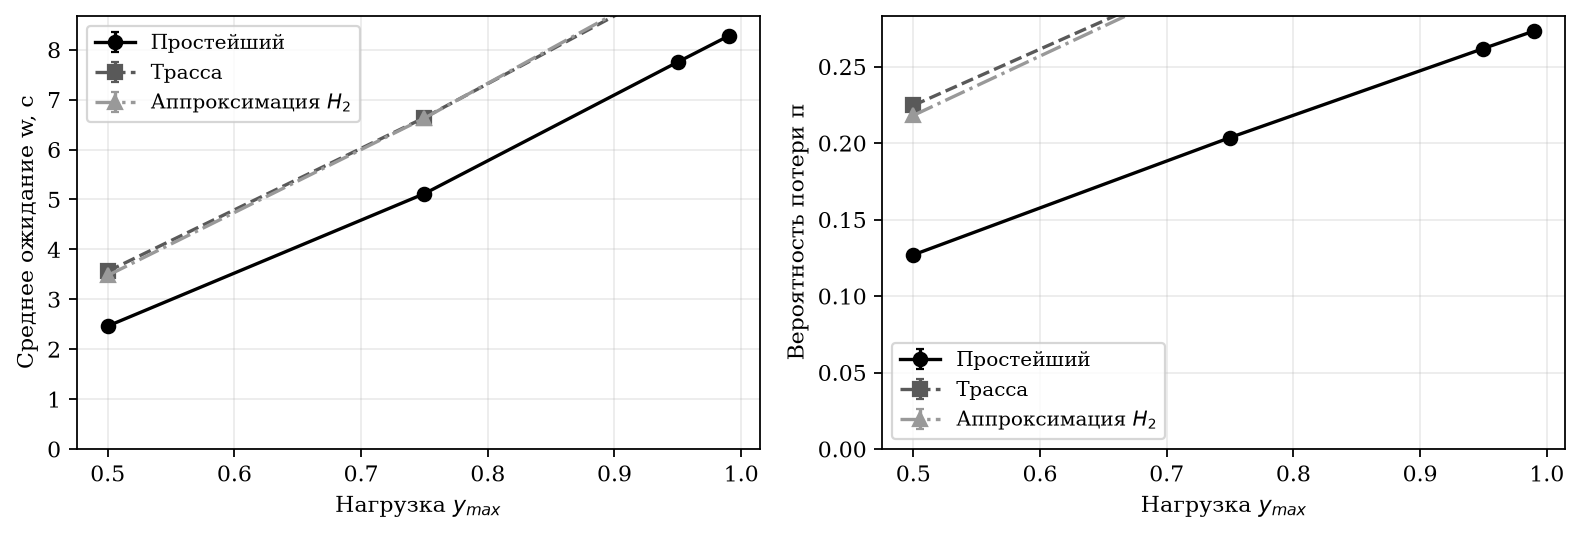

In [6]:
arrival_results = pd.read_csv(RESULTS/"arrival.csv")
display(arrival_results[["arrival","y","a","b","pi","pi_ci","w","w_ci","u","rho"]])
make_figures()
display(Image(filename=str(ROOT/"report-source"/"figures"/"arrival.png")))

### Форма 1 — Описание исследуемых вариантов организации системы

Строки и названия — из методички. Для трёх отдельных направлений ёмкость накопителя и коэффициенты вариации записываются вектором; все времена — в секундах. Остальные серии представлены в соответствующих CSV.

In [7]:
variants = [(f,y) for y in [.5,.75,.95,.99] for f in ["Т","А","П"]]
form1 = pd.DataFrame({str(i+1): {
    "Количество приборов": 3,
    "Ёмкость накопителя": "(2, 1, 0)",
    "Интервалы между заявками: ср. значение": round(a,6),
    "Вид потока": flow,
    "Длительность обслуживания: ср. значение": round(load*a/.45,6),
    "Коэф-т вариации": "(1; 1; 0,707107)"}
    for i,(flow,load) in enumerate(variants)})
display(form1.iloc[:,:6])
display(form1.iloc[:,6:])

,1,2,3,4,5,6
Количество приборов,3,3,3,3,3,3
Ёмкость накопителя,"(2, 1, 0)","(2, 1, 0)","(2, 1, 0)","(2, 1, 0)","(2, 1, 0)","(2, 1, 0)"
Интервалы между заявками: ср. значение,8.020778,8.020778,8.020778,8.020778,8.020778,8.020778
Вид потока,Т,А,П,Т,А,П
Длительность обслуживания: ср. значение,8.911976,8.911976,8.911976,13.367964,13.367964,13.367964
Коэф-т вариации,"(1; 1; 0,707107)","(1; 1; 0,707107)","(1; 1; 0,707107)","(1; 1; 0,707107)","(1; 1; 0,707107)","(1; 1; 0,707107)"


,7,8,9,10,11,12
Количество приборов,3,3,3,3,3,3
Ёмкость накопителя,"(2, 1, 0)","(2, 1, 0)","(2, 1, 0)","(2, 1, 0)","(2, 1, 0)","(2, 1, 0)"
Интервалы между заявками: ср. значение,8.020778,8.020778,8.020778,8.020778,8.020778,8.020778
Вид потока,Т,А,П,Т,А,П
Длительность обслуживания: ср. значение,16.932755,16.932755,16.932755,17.645713,17.645713,17.645713
Коэф-т вариации,"(1; 1; 0,707107)","(1; 1; 0,707107)","(1; 1; 0,707107)","(1; 1; 0,707107)","(1; 1; 0,707107)","(1; 1; 0,707107)"


Трасса и аппроксимация дают более высокие потери. Их интервалы часто короткие, но встречаются и длинные паузы. Поэтому накопители быстро заполняются, а затем приборы простаивают. Совпадение двух средних не означает совпадение характера потока.

### Дополнительная серия по фактической загрузке

Среднее обслуживание подбирается так, чтобы при простейшем входе фактическая средняя занятость трёх приборов равнялась $\rho_0=0{,}5;0{,}75;0{,}95;0{,}99$.

$$\frac13\sum_j(1-p_{0j}(b))=\rho_0,\qquad
p_{0j}(b)=\left(\sum_{k=0}^{K_j+E_j}(\lambda\alpha_jb)^k\right)^{-1}.$$

У П3 с E₂ нет накопителя, поэтому при простейшем входе занятость зависит от среднего обслуживания и та же формула применяется для вместимости один. После калибровки среднее обслуживание сохраняется при переходе к Т и А. Теперь требуемые значения фактической загрузки проверяются непосредственно имитацией.

,target_rho_M,arrival,a,b,rho,rho_ci,w,w_ci,pi
0,0.500000,M,8.020778,15.963714,0.499917,0.001561,6.990750,0.037045,0.246174
1,0.500000,T,8.020778,15.963714,0.424125,0.001380,8.600375,0.039593,0.360262
2,0.500000,A,8.020778,15.963714,0.422000,0.002312,8.664875,0.026837,0.361536
3,0.750000,M,8.020778,36.678474,0.749958,0.001705,26.247125,0.111835,0.507494
4,0.750000,T,8.020778,36.678474,0.636458,0.001148,26.710625,0.076094,0.581816
5,0.750000,A,8.020778,36.678474,0.623917,0.002877,26.701750,0.058783,0.588658
6,0.950000,M,8.020778,196.528359,0.950000,0.001016,189.809125,0.894864,0.883584
7,0.950000,T,8.020778,196.528359,0.908333,0.001183,183.398000,0.795742,0.888669
8,0.950000,A,8.020778,196.528359,0.903625,0.001955,182.840500,0.891241,0.888892
9,0.990000,M,8.020778,1048.171674,0.990083,0.000747,1040.945375,11.397877,0.977221


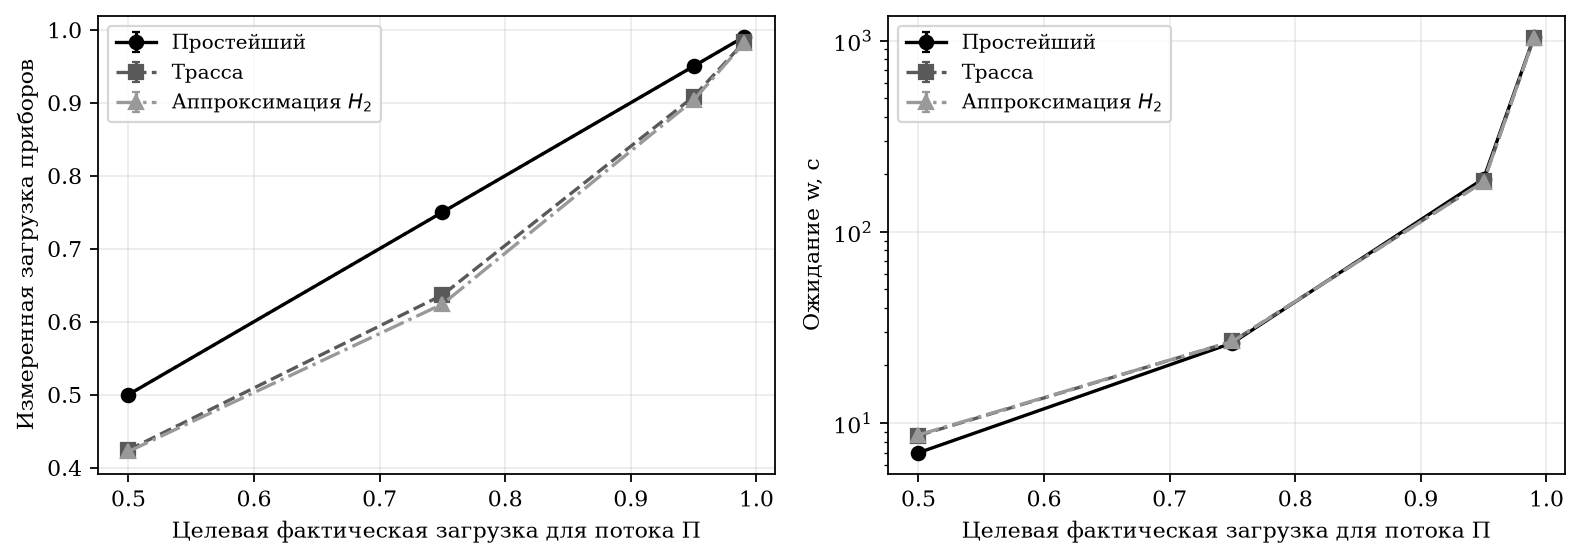

In [8]:
actual_load = pd.read_csv(RESULTS/"actual_load.csv")
display(actual_load[["target_rho_M","arrival","a","b","rho","rho_ci","w","w_ci","pi"]])
display(Image(filename=str(ROOT/"report-source"/"figures"/"actual_load.png")))

## 7. Закон обслуживания

В отдельной серии ко всем трём приборам применяется один закон при общем среднем $b$.

$$M:\ B=-b\ln U,\quad \nu_b=1;\qquad
E_2:\ B=-\frac b2(\ln U_1+\ln U_2),\quad \nu_b=\frac1{\sqrt2}.$$

Для $H_2$ коэффициент вариации равен 2. Используется смесь двух экспонент с тем же средним и $q_b=\frac12(1+\sqrt{3/5})$.

Большая вариация создаёт редкие длительные обслуживания, во время которых образуется очередь.

,service,y,w,w_ci,u,pi
0,M,0.500000,2.464125,0.027258,11.376625,0.127417
1,M,0.750000,5.114750,0.040243,18.477000,0.203419
2,M,0.950000,7.755000,0.073896,24.682000,0.261987
3,M,0.990000,8.276375,0.110602,25.915625,0.273467
4,E2,0.500000,2.029250,0.026189,10.935750,0.115119
5,E2,0.750000,4.396250,0.058734,17.750250,0.186244
6,E2,0.950000,6.831125,0.081961,23.746250,0.243225
7,E2,0.990000,7.368375,0.115090,24.994500,0.253950
8,H2,0.500000,3.574500,0.061566,12.443750,0.155213
9,H2,0.750000,6.681375,0.109848,19.984250,0.238958


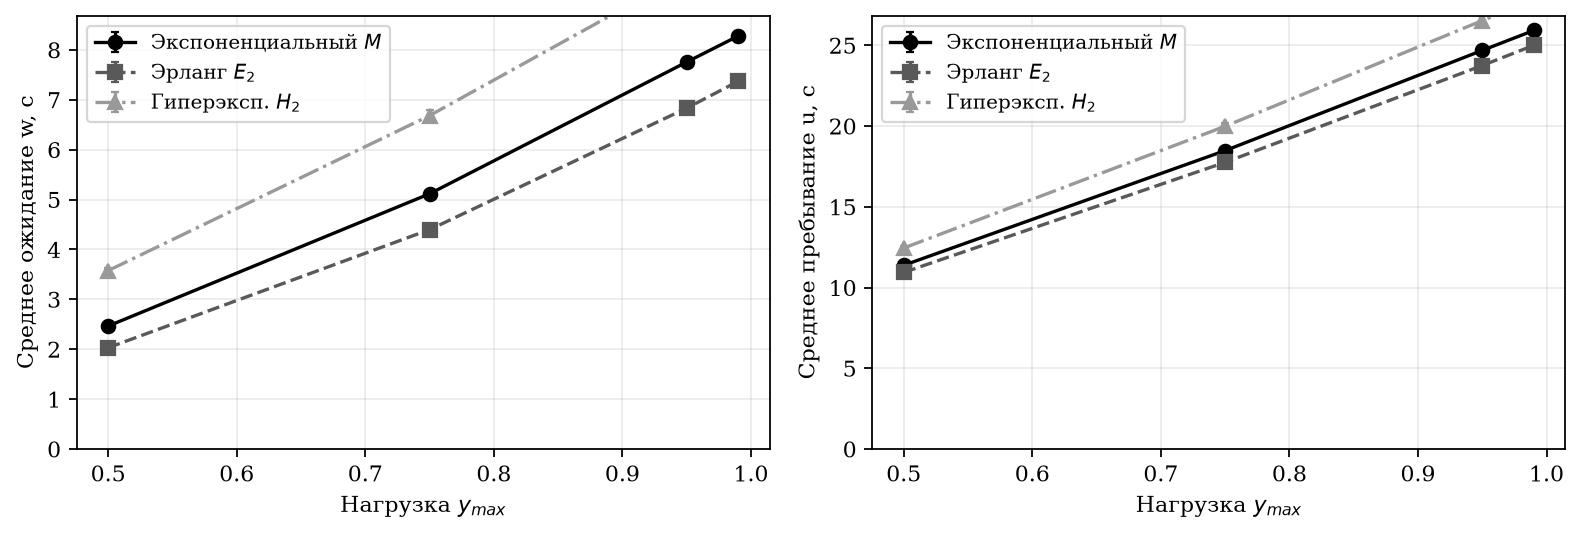

In [9]:
service_results = pd.read_csv(RESULTS/"service.csv")
display(service_results[["service","y","w","w_ci","u","pi"]])
display(Image(filename=str(ROOT/"report-source"/"figures"/"service.png")))

## 8. Длительность переходного процесса в системе

По методичке считаем **прошедшие через систему заявки**: завершения обслуживания и отказы. В GPSS их считает `TERMINATE 1`. Для нескольких контрольных точек выполняются последовательные `START` с приращениями счётчика. Вспомогательная функция `passed_path` из `methodical_tables.py` служит отдельной проверкой Python.

Начальное состояние пустое. Сетка $N=10,20,50,100,200,300,600,1000,3000,10000,30000,100000$ в одном прогоне. Выполнено по 12 независимых повторений. Исследованы нагрузки $0{,}1;0{,}3;0{,}5;0{,}7;0{,}9$ обоими способами п. 2.2.2: изменением $b$ при фиксированном $a$ и изменением $a$ при фиксированном $b=5$ с. Потоки Т, А и П, обслуживание $(M,M,E_2)$.

**Форма 2 — Результаты имитационных экспериментов.** Названия столбцов и их смысл сохранены из задания. В столбце «Заявок» указано $N_\Sigma=12N$, «Потери» — целое суммарное число отказов. Средние и СКО объединены по наблюдениям всех прогонов. Загрузка — суммарная занятость, делённая на суммарное время и три прибора.

$$\text{П}(\%)=\frac{|\pi_N-\pi_{N_{\rm пред}}|}{|\pi_N|}\,100\%,\quad
\text{О}(\%)=\frac{|w_N-w_{N_{\rm пред}}|}{|w_N|}\,100\%,\quad
\text{Д}(\%)=\frac{\varepsilon_w}{w_N}\,100\%.$$

Знаменатель П(%) и О(%) — **текущее значение**, как в числовом примере методички: $|0{,}29-0{,}25|/0{,}29\approx13{,}8\%$, $|11{,}835-10{,}785|/11{,}835\approx8{,}9\%$.

«Дов.инт.» содержит полуинтервал $\pm\varepsilon_w$ при доверии 0,95. Если текущее значение нулевое, относительное изменение не определено. Интервал рассчитан по независимым повторам, а не по зависимым ожиданиям отдельных заявок.

Для $S_r=\sum_i W_{ri}$, $n_r$ — числа зарегистрированных ожиданий:
$$w_N=\frac{\sum_rS_r}{\sum_rn_r},\quad
\varepsilon_w=t_{0{,}975;R-1}
\frac{\sqrt{\dfrac{R}{R-1}\sum_r(S_r-w_N n_r)^2}}{\sum_rn_r}+\Delta_{\rm окр},\quad R=12.$$

Это приближённый интервал дельта-метода. Допуск округления среднего $\Delta_{\rm окр}=0{,}0005$ с. Интервал не подтверждает стационарность при малом числе прошедших заявок.

**Форма 2. Трасса поток; K=3, E=(2,1,0), a=8.020778, b=16.041557, КВ=(1;1;0,707107).**

,Заявок,Потери,Вер-ть потери,П(%),Длина очер.,Загрузка,Ср.вр.ож.,О(%),СКО вр.ож.,Дов.инт. (±),Д(%)
348,120,35,0.291667,NaN,0.744531,0.560173,6.529259,NaN,12.458812,2.649441,40.577981
349,240,86,0.358333,18.604651,0.548645,0.409324,4.753105,37.368295,9.931588,1.435285,30.196780
350,600,195,0.325000,10.256410,0.683170,0.467094,6.551518,27.450327,13.432275,1.580747,24.127951
351,1200,441,0.367500,11.564626,0.675337,0.420935,7.940765,17.495129,15.088494,0.903912,11.383180
352,2400,944,0.393333,6.567797,0.760354,0.470386,8.270986,3.992524,14.705517,0.841234,10.170908
353,3600,1305,0.362500,8.505747,0.663599,0.426473,8.216363,0.664805,16.155648,0.866151,10.541784
354,7200,2622,0.364167,0.457666,0.688571,0.431305,8.625647,4.744964,16.769912,0.616157,7.143313
355,12000,4384,0.365333,0.319343,0.703257,0.432530,8.816272,2.162197,16.529533,0.492593,5.587312
356,36000,12991,0.360861,1.239320,0.685667,0.427528,8.586104,2.680700,15.935403,0.314518,3.663100
357,120000,43516,0.362633,0.488709,0.682834,0.424444,8.585640,0.005411,15.850980,0.181954,2.119287


**Форма 2. Аппроксимирующий поток; K=3, E=(2,1,0), a=8.020778, b=16.041557, КВ=(1;1;0,707107).**

,Заявок,Потери,Вер-ть потери,П(%),Длина очер.,Загрузка,Ср.вр.ож.,О(%),СКО вр.ож.,Дов.инт. (±),Д(%)
228,120,44,0.366667,NaN,0.367271,0.305132,4.454641,NaN,10.267742,1.723771,38.696067
229,240,84,0.350000,4.761905,0.360656,0.324396,4.573227,2.593037,9.880683,1.122017,24.534471
230,600,201,0.335000,4.477612,0.541737,0.379142,6.137418,25.486141,12.658585,1.410652,22.984451
231,1200,400,0.333333,0.500000,0.558587,0.386657,6.995462,12.265730,13.400878,1.106196,15.813044
232,2400,844,0.351667,5.213270,0.655635,0.409920,8.163360,14.306582,15.395462,1.045111,12.802459
233,3600,1267,0.351944,0.078927,0.702492,0.423497,8.747635,6.679238,16.228070,0.581580,6.648420
234,7200,2607,0.362083,2.800153,0.716890,0.426209,8.998724,2.790272,16.738250,0.548005,6.089810
235,12000,4403,0.366917,1.317284,0.705638,0.423792,9.025824,0.300246,16.582821,0.399243,4.423340
236,36000,13039,0.362194,1.303781,0.696729,0.429113,8.702409,3.716390,15.734849,0.241171,2.771311
237,120000,43571,0.363092,0.247106,0.687952,0.424895,8.636914,0.758314,15.846478,0.197905,2.291382


**Форма 2. Простейший поток; K=3, E=(2,1,0), a=8.020778, b=16.041557, КВ=(1;1;0,707107).**

,Заявок,Потери,Вер-ть потери,П(%),Длина очер.,Загрузка,Ср.вр.ож.,О(%),СКО вр.ож.,Дов.инт. (±),Д(%)
288,120,33,0.275000,NaN,0.387312,0.412942,3.009920,NaN,7.959982,1.621859,53.883797
289,240,63,0.262500,4.761905,0.446694,0.462878,3.902990,22.881683,9.912018,1.377264,35.287408
290,600,144,0.240000,9.375000,0.584474,0.478808,5.906832,33.924148,12.998242,1.781188,30.154705
291,1200,279,0.232500,3.225806,0.623594,0.489818,6.536072,9.627179,14.231000,1.161943,17.777394
292,2400,599,0.249583,6.844741,0.722189,0.505687,7.563782,13.587252,15.852322,1.096856,14.501425
293,3600,889,0.246944,1.068616,0.694700,0.500755,7.403098,2.170489,15.699808,0.888939,12.007664
294,7200,1766,0.245278,0.679502,0.687418,0.502540,7.394206,0.120262,15.309809,0.555290,7.509800
295,12000,2979,0.248250,1.197270,0.687725,0.505076,7.369493,0.335343,15.160073,0.554520,7.524528
296,36000,8884,0.246778,0.596578,0.652979,0.500730,6.971677,5.706165,14.270444,0.187509,2.689576
297,120000,29608,0.246733,0.018013,0.658894,0.501181,7.026269,0.776972,14.415794,0.144831,2.061277


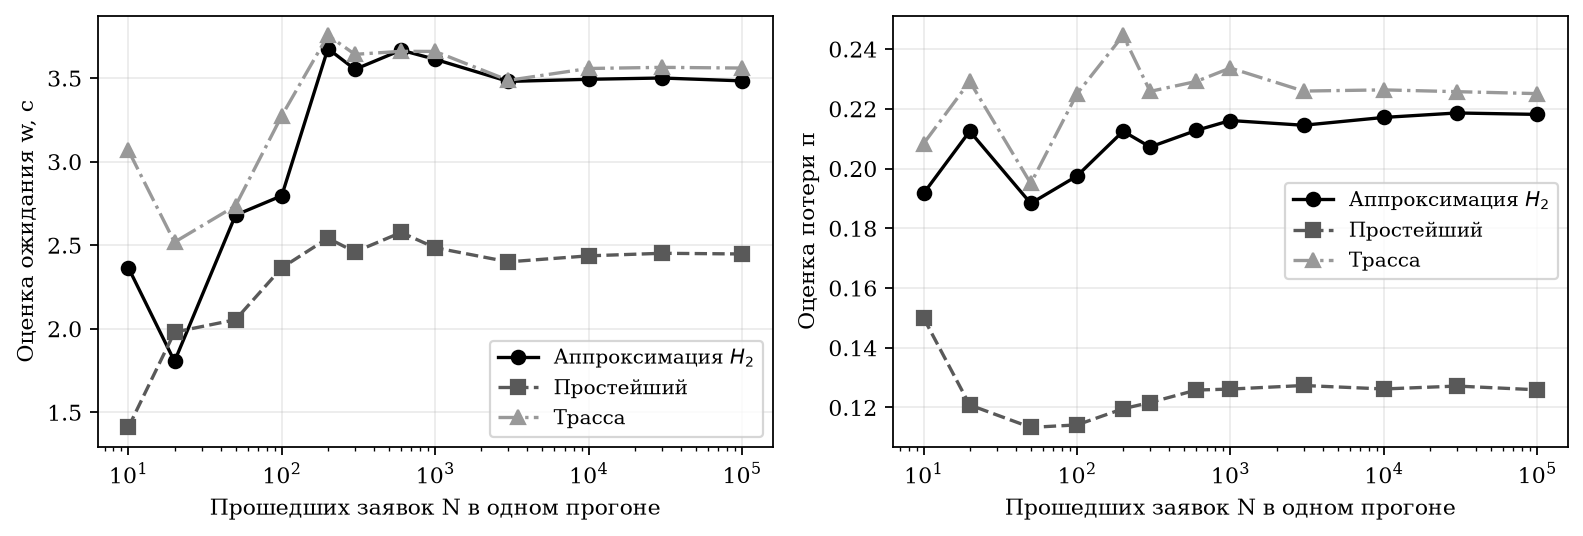

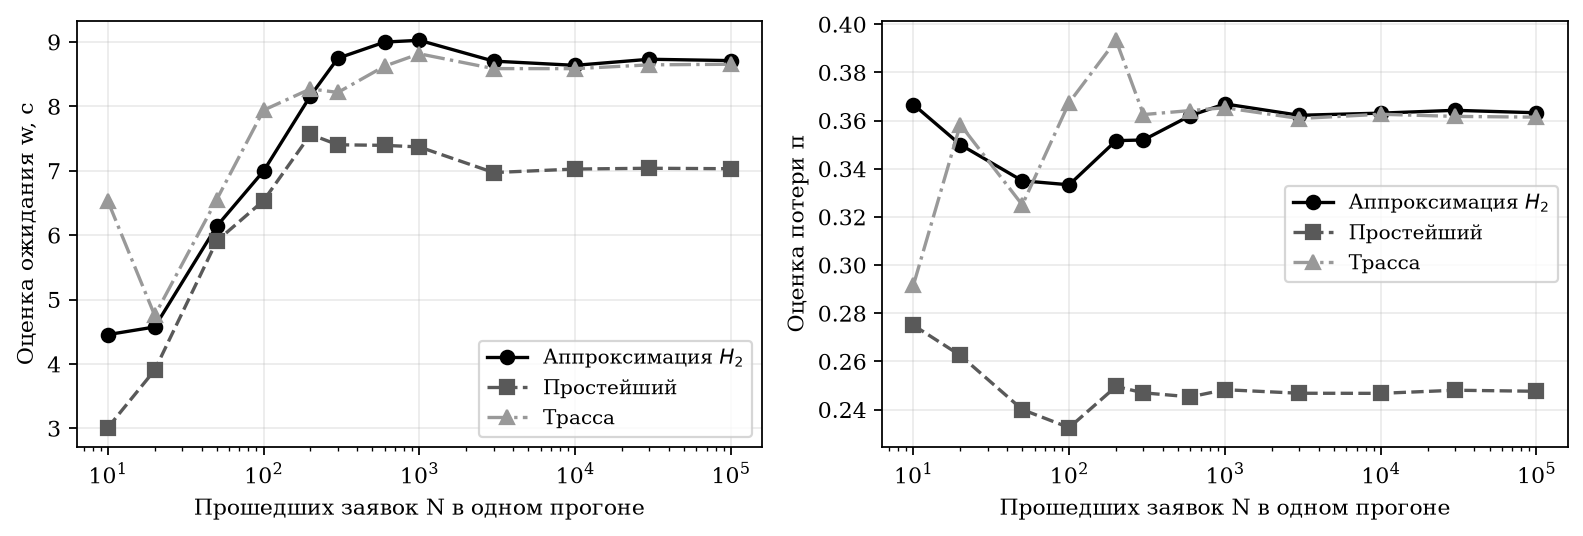

In [10]:
from methodical_tables import stability_table
transient = pd.read_csv(RESULTS/"form2.csv")
columns = {"passed_total":"Заявок", "lost":"Потери", "pi":"Вер-ть потери",
    "P_percent":"П(%)", "l":"Длина очер.", "rho":"Загрузка", "w":"Ср.вр.ож.",
    "O_percent":"О(%)", "sw":"СКО вр.ож.", "w_ci":"Дов.инт. (±)", "D_percent":"Д(%)"}
for flow, label in [("T","Трасса"),("A","Аппроксимирующий"),("M","Простейший")]:
    selected = transient[(transient.arrival==flow)&(transient.y==.9)&(transient.way=="b")]
    display(Markdown(f"**Форма 2. {label} поток; K=3, E=(2,1,0), a={a:.6f}, b={.9*a/.45:.6f}, КВ=(1;1;0,707107).**"))
    display(selected[list(columns)].rename(columns=columns))
display(Image(filename=str(ROOT/"report-source"/"figures"/"transient_50.png")))
display(Image(filename=str(ROOT/"report-source"/"figures"/"transient_90.png")))

Для практической оценки $N_{\text{уст}}$ выбран порог 5%: на всех последующих точках сетки отклонения $w$ и $\pi$ от последних оценок меньше 5%, а Д(%) меньше 5%. Порог и сетка выбраны исследователем. Это критерий статистической устойчивости, объединяющий разгон и погрешность, а не универсальное физическое время перехода. При малой нагрузке ожидания редки, поэтому точная относительная оценка их среднего может требовать большого числа заявок.

y            0.100000  0.300000  0.500000  0.700000  0.900000
way arrival                                                  
a   A           10000      3000      3000      3000      1000
    M           10000      3000      3000      3000      3000
    T            3000      3000      3000      3000      3000
b   A           10000      3000      3000      3000      1000
    M           30000      3000      3000      3000      3000
    T            3000      3000      3000      3000      3000

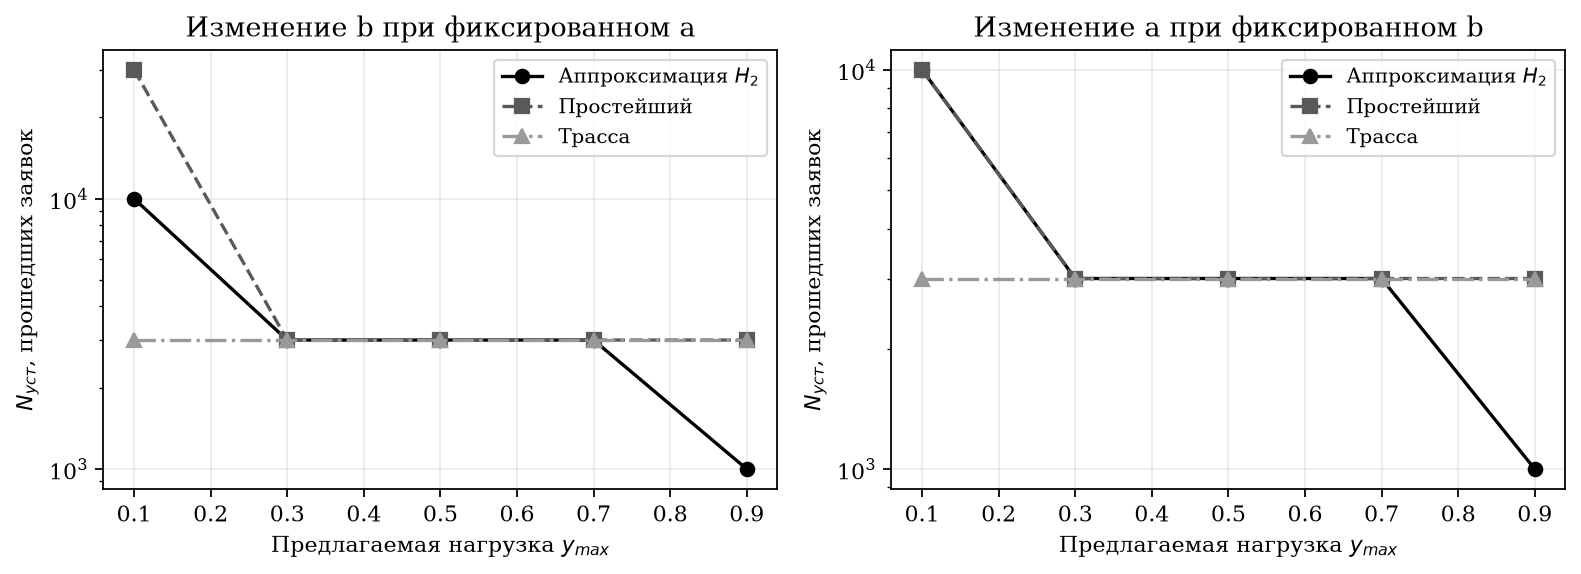

Два способа дали одинаковые N: при одинаковом b/a меняется только масштаб времени.
При изменении a интервалы трассы масштабируются на a/a_УИР1, порядок сохраняется.


In [11]:
stable = stability_table(transient)
display(stable.pivot(index=["way","arrival"],columns="y",values="N_stable"))
display(Image(filename=str(ROOT/"report-source"/"figures"/"transient_loads.png")))
print("Два способа дали одинаковые N: при одинаковом b/a меняется только масштаб времени.")
print("При изменении a интервалы трассы масштабируются на a/a_УИР1, порядок сохраняется.")

## 9. Размер накопителя

Во всех трёх направлениях устанавливается одинаковое $E$. Так сравнивается семейство буферных конфигураций с исходной маршрутизацией. Для определения минимального наблюдаемого $E^*$ проверяются максимальная очередь без ограничений и соседние значения $E^*-1,E^*$.

Ноль потерь за конечный опыт не означает нулевую теоретическую вероятность. Порог относится к восьми повторениям и 480 000 прошедших заявок.

,y,E,lost_total,arrivals_total,pi,w,u
0,0.500000,0,133915,480000,0.278990,0.000000,8.892625
1,0.500000,1,47668,480002,0.099308,2.370875,11.275750
2,0.500000,2,19643,479999,0.040923,3.862625,12.766125
3,0.500000,4,4162,480003,0.008671,5.285875,14.190500
4,0.500000,8,234,480015,0.000487,5.960125,14.863750
5,0.500000,16,0,480013,0.000000,6.026375,14.929625
6,0.500000,32,0,480013,0.000000,6.026375,14.929625
7,0.500000,64,0,480013,0.000000,6.026375,14.929625
8,0.500000,128,0,480013,0.000000,6.026375,14.929625
9,0.500000,256,0,480013,0.000000,6.026375,14.929625


[{'y': 0.5,
  'E_star_observed': 15,
  'checks': [{'E': 14, 'lost': 1, 'model': 'g_smo_E14_50'},
   {'E': 15, 'lost': 0, 'model': 'g_smo_E15_50'}],
  'trials': 480000},
 {'y': 0.9,
  'E_star_observed': 72,
  'checks': [{'E': 71, 'lost': 1, 'model': 'g_smo_E71_90'},
   {'E': 72, 'lost': 0, 'model': 'g_smo_E72_90'}],
  'trials': 480000}]

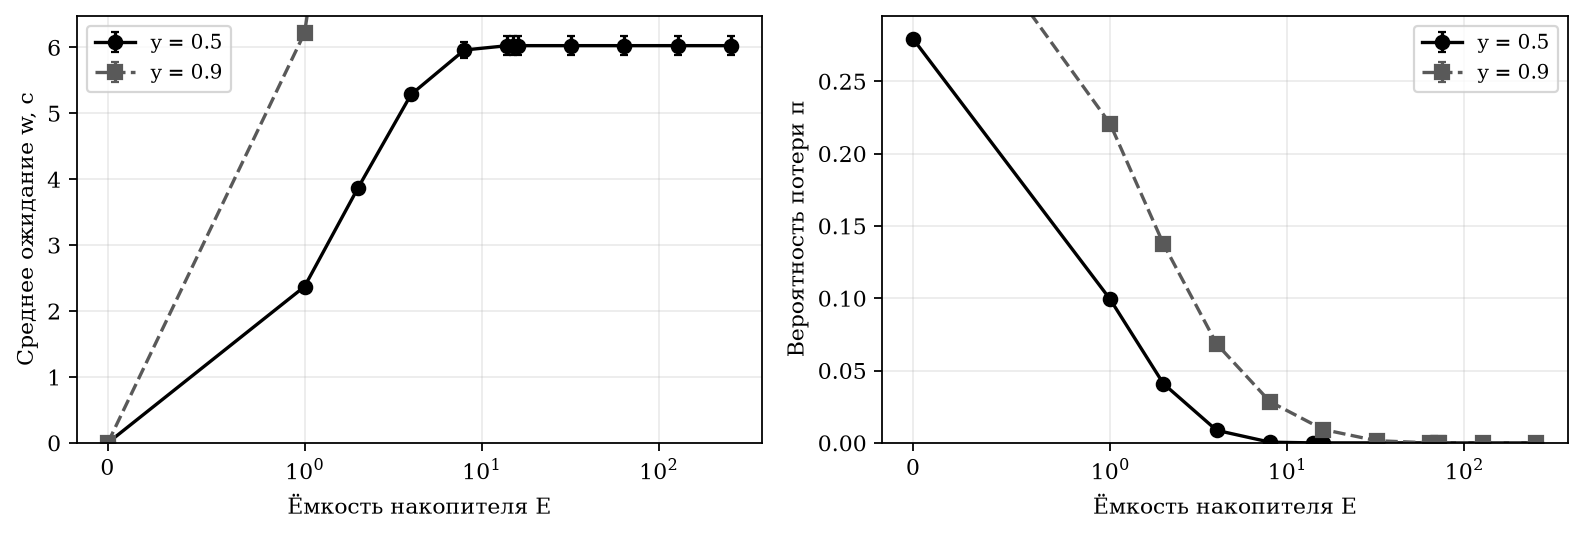

In [12]:
buffer_results = pd.read_csv(RESULTS/"buffer.csv")
display(buffer_results[["y","E","lost_total","arrivals_total","pi","w","u"]])
display(json.loads((RESULTS/"buffer_threshold.json").read_text()))
display(Image(filename=str(ROOT/"report-source"/"figures"/"buffer.png")))

## 10. Число приборов
В каждом из трёх направлений меняется число приборов от 1 до 3. Всего получается 3, 6 или 9 приборов. Слева сохраняются вход и среднее обслуживание; справа сохраняется предлагаемая нагрузка на один прибор, поэтому среднее обслуживание увеличивается вместе с числом приборов.

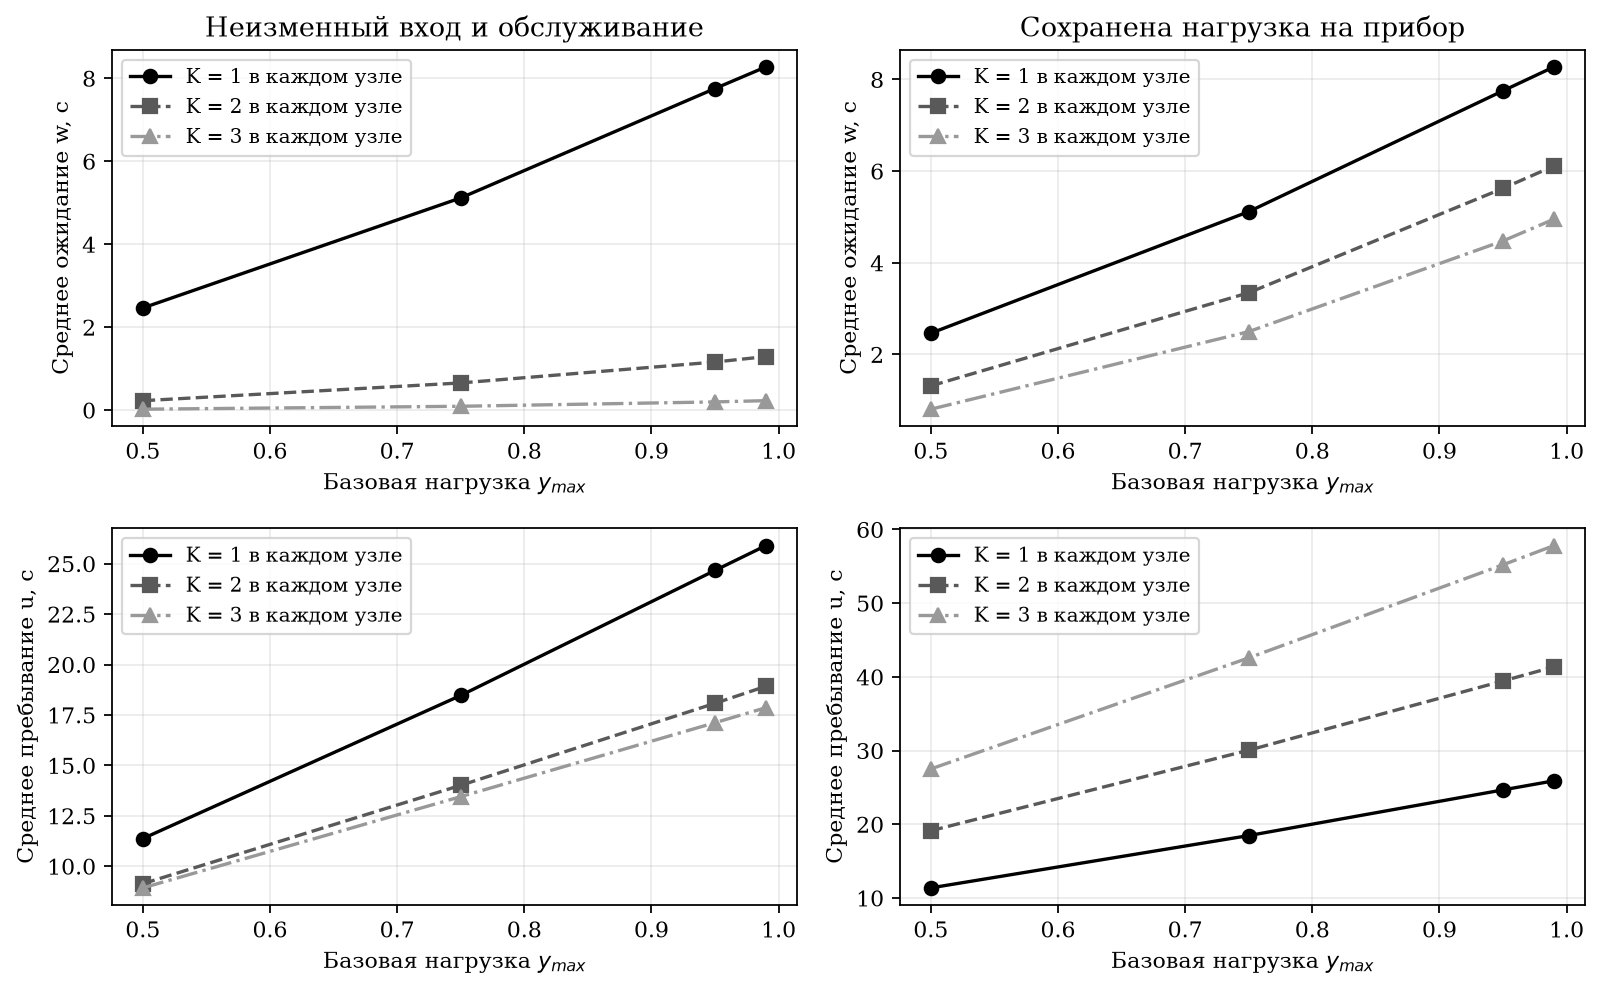

In [13]:
display(Image(filename=str(ROOT/"report-source"/"figures"/"servers.png")))

## 11. Независимая проверка M/M/1 и M/G/1

Отдельный проверочный опыт: один прибор, почти неограниченный накопитель, $a=8$ с, $b=4$ с, $\rho=0{,}5$.

$$w=\frac{\rho b(1+\nu_b^2)}{2(1-\rho)},\qquad u=w+b.$$

Для M, E₂, H₂ теоретические ожидания равны 4, 3 и 10 с. Эти формулы не применяются к ограниченным накопителям исходной СМО.

In [14]:
mg1 = pd.read_csv(RESULTS/"mg1_validation.csv")
display(mg1[["law","exact_w","w","w_ci","exact_u","u"]])
assert ((mg1.w-mg1.exact_w).abs() < mg1.w_ci).all()

,law,exact_w,w,w_ci,exact_u,u
0,M,4.000000,3.987667,0.022619,8.000000,7.986000
1,E2,3.000000,2.991500,0.018078,7.000000,6.992333
2,H2,10.000000,10.109833,0.125667,14.000000,14.116917


## 12. Вид распределений времени

$$\nu_w=\frac{\sigma_w}{w},\qquad \nu_u=\frac{\sigma_u}{u}.$$

КВ больше единицы позволяет предложить H₂ как двухмоментную аппроксимацию. КВ около единицы — экспоненту, меньше единицы — Эрланга. **По одному КВ нельзя однозначно установить закон.** У ожидания дополнительно есть масса в нуле, потому что часть заявок сразу попадает в свободный прибор.

Для положительной части ожидания отдельно от массы в нуле используются моменты:
$$p_0=P(W=0),\qquad w_+=\frac{w}{1-p_0},\qquad
\nu_+^2=(1-p_0)\frac{\overline{W^2}}{w^2}-1.$$
Это дополнительная проверка формы: большой КВ всего ожидания может возникать из-за большого числа нулей. Он не доказывает гиперэкспоненциальность положительных ожиданий.

,n,mean,cv,p_zero,cv_positive
smo_w,298629.000000,9.416809,1.802833,0.548406,0.958834
smo_u,298629.000000,26.307627,0.885706,0.000000,0.885704
network_w,320000.000000,349.810250,2.037103,0.245644,1.698460
network_u,320000.000000,402.294500,1.854197,0.000000,1.854194


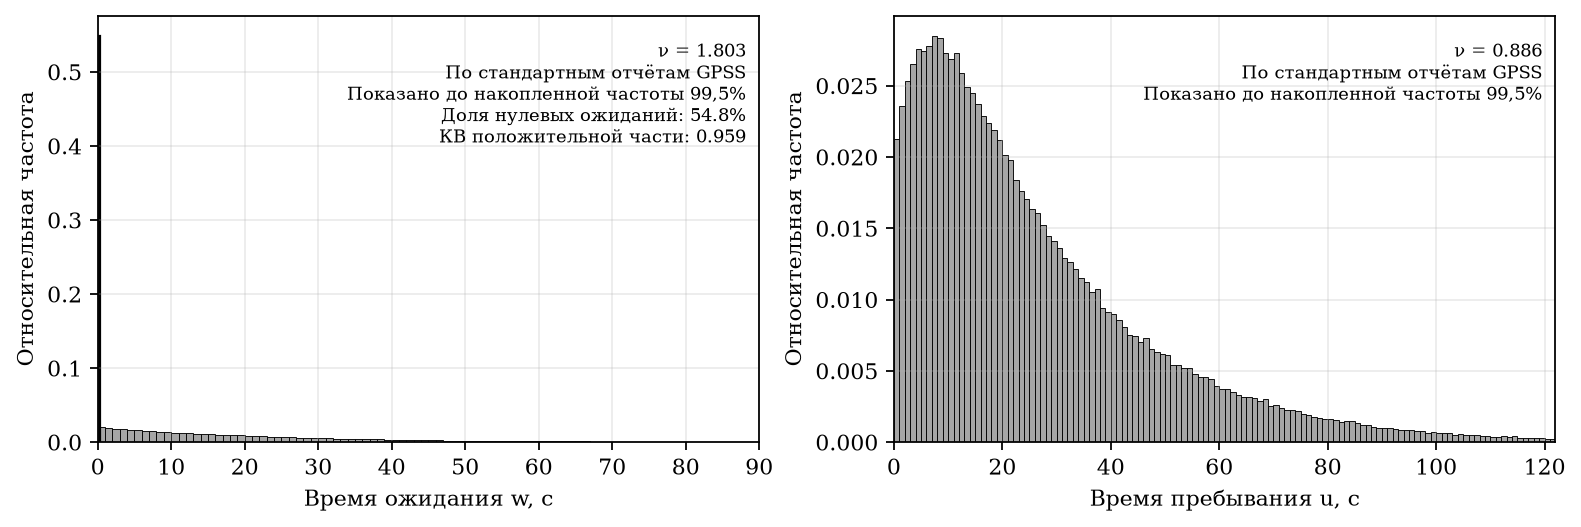

In [15]:
histograms = json.loads((RESULTS/"histograms.json").read_text())
display(pd.DataFrame({k:{c:v[c] for c in ["n","mean","cv","p_zero","cv_positive"]} for k,v in histograms.items()}).T)
display(Image(filename=str(ROOT/"report-source"/"figures"/"hist_smo.png")))

In [16]:
display(arrival_results[arrival_results.y.isin([.5,.95])][
    ["arrival","y","w","sw","cvw","u","su","cvu"]])
print("Для независимых наблюдений исправленная дисперсия с делением на n−1 несмещённа. Её корень не является несмещённой оценкой СКО.")
print("Ожидания одного прогона могут быть зависимыми: точность среднего оценивается по независимым повторениям.")

,arrival,y,w,sw,cvw,u,su,cvu
0,M,0.500000,2.462875,6.472125,2.628029,11.370375,10.608750,0.933019
2,M,0.950000,7.753375,15.570625,2.008366,24.666625,22.324750,0.905064
4,T,0.500000,3.559750,7.690000,2.160323,12.463250,11.406250,0.915192
6,T,0.950000,9.358125,16.960250,1.812369,26.249625,23.310500,0.888022
8,A,0.500000,3.476625,7.625250,2.193281,12.378500,11.368875,0.918433
10,A,0.950000,9.417000,16.976625,1.802752,26.308000,23.300375,0.885673


Для независимых наблюдений исправленная дисперсия с делением на n−1 несмещённа. Её корень не является несмещённой оценкой СКО.
Ожидания одного прогона могут быть зависимыми: точность среднего оценивается по независимым повторениям.


## 13. Сетевая часть, вариант А/Б = 6/6

**Часть 2 «Исследование свойств сетей массового обслуживания (СеМО)».**

Тип М1, три узла. $K=(1,4,1)$, $b=(1,15,10)$ с. Из У1 заявка с вероятностью $p_{10}=0{,}2$ выходит через «0» или завершает цикл в закрытой сети, с $p_{12}=0{,}3$ идёт в У2, с оставшейся вероятностью $0{,}5$ — в У3. Из У2 и У3 возвращается в У1. У закрытой сети переход через «0» мгновенный.

Число из колонки `p13` таблицы 2 не переносится на М1: оно предназначено для М3. У М1 последняя вероятность находится из суммы исходящих вероятностей.

В У3 исследуются M, E₂, H₂ с КВ 2. Очереди сети неограниченны, FIFO.

In [17]:
display(pd.DataFrame({"Узел": [1,2,3], "Приборов": SERVERS,
                      "Среднее обслуживание, с": MEANS, "Посещений за цикл": VISITS}))
P_closed = np.array([[.2,.3,.5],[1,0,0],[1,0,0]])
P_open = np.array([[0,.3,.5],[1,0,0],[1,0,0]])
display(pd.DataFrame(P_closed, index=["У1","У2","У3"], columns=["У1","У2","У3"]))
print("Открытая сеть: сумма первой строки 0,8; оставшиеся 0,2 — выход")

,Узел,Приборов,"Среднее обслуживание, с",Посещений за цикл
0,1,1,1.000000,5.000000
1,2,4,15.000000,1.500000
2,3,1,10.000000,2.500000


,У1,У2,У3
У1,0.200000,0.300000,0.500000
У2,1.000000,0.000000,0.000000
У3,1.000000,0.000000,0.000000


Открытая сеть: сумма первой строки 0,8; оставшиеся 0,2 — выход


## 14. Коэффициенты передач и узкое место

Нормируем по одному прохождению через «0». По п. 6.7.11 теории производительность сети обозначается $\lambda_0$, сетевое время пребывания — $U$; $w_j,u_j$ относятся к одному посещению узла. $N_0$ — число прохождений через нулевую точку за время $T$, $N_j$ — число обслуживаний в узле:

$$\lambda_0=\frac{N_0}{T},\qquad \alpha_j=\frac{N_j}{N_0}.$$

$$\alpha=(5;1{,}5;2{,}5),\qquad D_j=\alpha_j b_j,\qquad
\lambda_{0,\text{пред}}=\min_j\frac{K_j}{D_j}=0{,}04\ \text{с}^{-1}.$$

Узкое место — У3. В открытой сети нужен строгий запас $\lambda_0<0{,}04$. Число обслуживаний в узлах больше числа завершённых циклов, поскольку одна заявка может посещать узлы несколько раз.

Предельная производительность 0.04 цикла/с


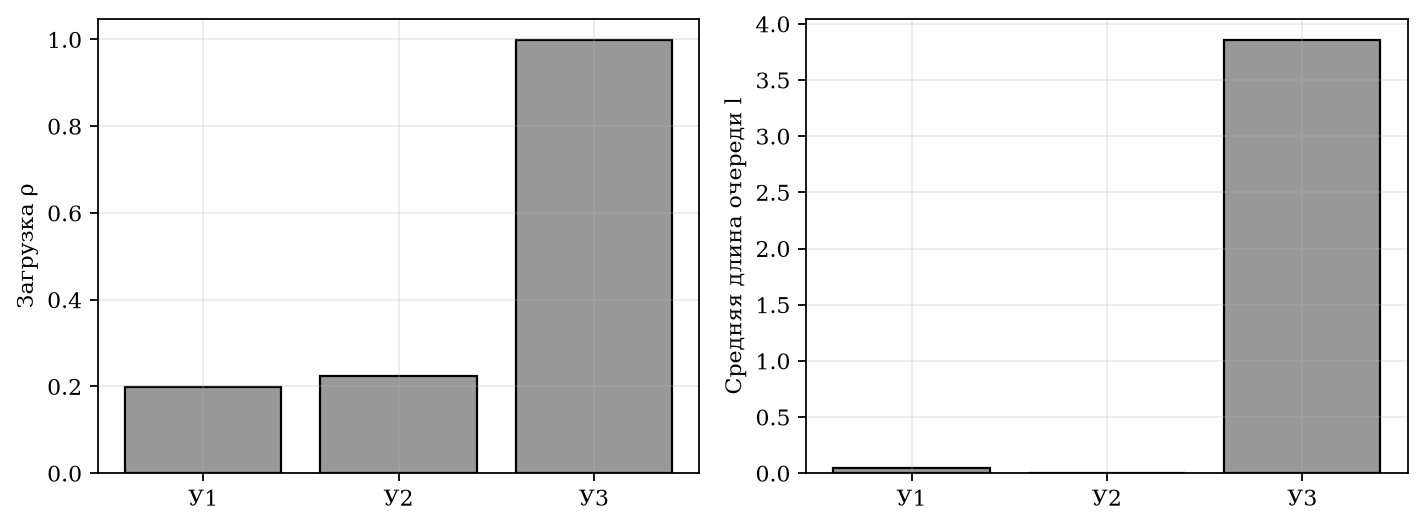

In [18]:
capacity = np.min(np.array(SERVERS)/(VISITS*np.array(MEANS)))
print("Предельная производительность", capacity, "цикла/с")
display(Image(filename=str(ROOT/"report-source"/"figures"/"node_bottleneck.png")))

## 15. Закрытая сеть и критическое число заявок

Функция `network` хранит календарь событий. По событию освобождает прибор, начинает обслуживание следующей заявки FIFO и выбирает следующий узел. Число заявок в закрытой сети постоянно.

Для экспоненциального случая выполнена отдельная точная проверка по нормирующим суммам.

$$g_j(n)=g_j(n-1)\frac{\alpha_jb_j}{\min(n,K_j)},\qquad
G(M)=\sum_{n_1+n_2+n_3=M}\prod_jg_j(n_j),\qquad
\lambda_0(M)=\frac{G(M-1)}{G(M)}.$$

$M^*$ — первая точка, в которой приращение производительности относительно $M-1$ меньше 1% и остаётся таким на дальнейшей сетке до 30. Здесь $M^*=6$.

,M,through,w,u,l,m
0,1,0.019048,0.000000,52.500000,0.000000,1
1,2,0.030826,12.380952,64.880952,0.381651,2
2,3,0.036682,29.284404,81.784404,1.074205,3
3,4,0.038994,50.079085,102.579085,1.952799,4
4,5,0.039720,73.380802,125.880802,2.914694,5
5,6,0.039926,97.777542,150.277542,3.903878,6
6,7,0.039981,122.582360,175.082360,4.900988,7
7,8,0.039995,147.523371,200.023371,5.900245,8
8,9,0.039999,172.506410,225.006410,6.900060,9
9,10,0.040000,197.501713,250.001713,7.900014,10


,M,through,through_ci,w,u
0,1,0.019061,0.000127,0.000000,52.466500
1,2,0.030866,0.000205,12.332875,64.800125
2,3,0.036717,0.000244,29.245125,81.711750
3,4,0.039015,0.000263,50.067250,102.535375
24,5,0.039729,0.000269,73.393875,125.861125
4,6,0.039927,0.000270,97.814500,150.280250
25,7,0.039980,0.000270,122.630750,175.093500
5,8,0.039994,0.000270,147.574875,200.039125
6,12,0.039997,0.000269,247.572500,300.038625
7,20,0.039996,0.000269,447.625000,500.092375


M* = 6


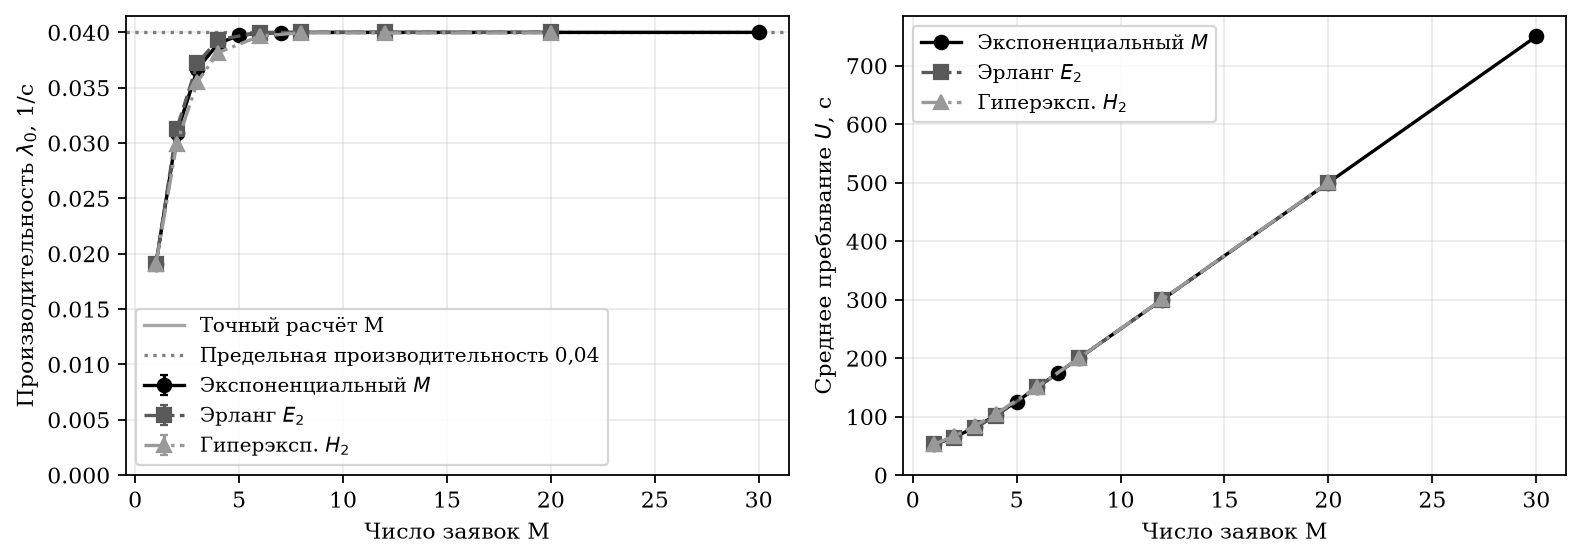

In [19]:
closed_results = pd.read_csv(RESULTS/"closed.csv")
closed_reference = pd.read_csv(RESULTS/"closed_exact.csv")
display(closed_reference.head(10))
display(closed_results[closed_results.law=="M"].sort_values("M")[["M","through","through_ci","w","u"]])
print("M* =", meta["Mstar"])
display(Image(filename=str(ROOT/"report-source"/"figures"/"closed.png")))

## 16. Устранение узкого места
При M = 6 сравниваются два отдельных изменения: уменьшение b₃ с 10 до 5 с и увеличение K₃ с 1 до 2. В обоих случаях предельная мощность У3 удваивается. Ускорение сокращает обслуживание, а второй прибор разрешает обслуживать одновременно две заявки.

,change,M,through,through_ci,w,u
0,base,6,0.039927,0.000270,97.814500,150.280250
1,faster,6,0.077161,0.000406,37.846625,77.763625
2,parallel,6,0.075788,0.000399,26.754875,79.167625


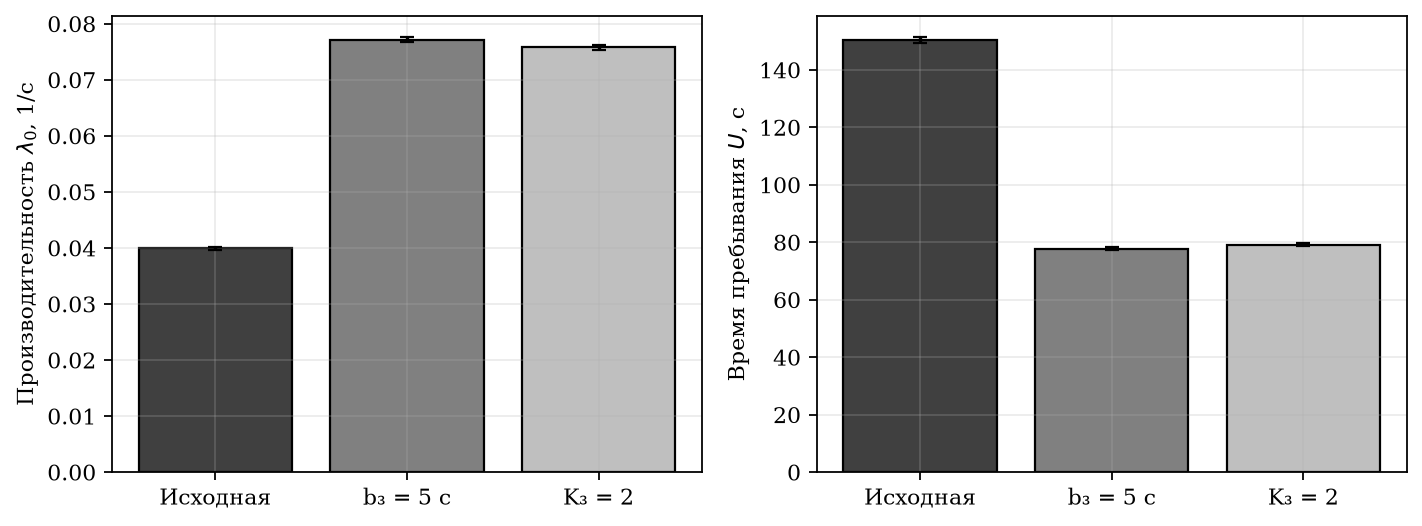

In [20]:
display(pd.read_csv(RESULTS/"bottleneck.csv")[["change","M","through","through_ci","w","u"]])
display(Image(filename=str(ROOT/"report-source"/"figures"/"bottleneck.png")))

## 17. Открытая сеть при согласованной интенсивности

Для прямого сравнения выбрана закрытая сеть с $M=3$. Для каждого закона внешняя интенсивность открытой сети равна производительности соответствующей закрытой. Это оставляет запас до перегрузки.

Интенсивности согласованы со средними оценками производительности ЗСеМО в GPSS отдельно для каждого закона обслуживания. При $M^*=6$ теоретическая интенсивность M-сети уже около $0{,}039926$ с⁻¹, а загрузка У3 около $0{,}99815$. Такая открытая сеть требует существенно более длинных экспериментов; её стационарное ожидание не выдано за точно измеренное коротким прогоном.

При равной интенсивности закрытая сеть ограничивает число одновременных заявок. В открытой это число случайно и может быть большим. Поэтому средние времена различаются.

,law,arrival,lambda_,through,w,u,u_ci
0,M,M,0.036717,0.036668,270.503000,322.814500,27.227718
1,M,D,0.036717,0.036714,185.137625,237.599125,26.637157
6,E2,M,0.037235,0.037216,315.071375,367.644500,59.168400
7,E2,D,0.037235,0.037232,195.996500,248.440875,27.476399
12,H2,M,0.035539,0.035606,302.367125,354.851250,13.244701
13,H2,D,0.035539,0.035541,213.922625,266.337250,18.940048


Точный M-случай при заданной интенсивности GPSS: W = 280.7843056112912 ; U = 333.2843056112912


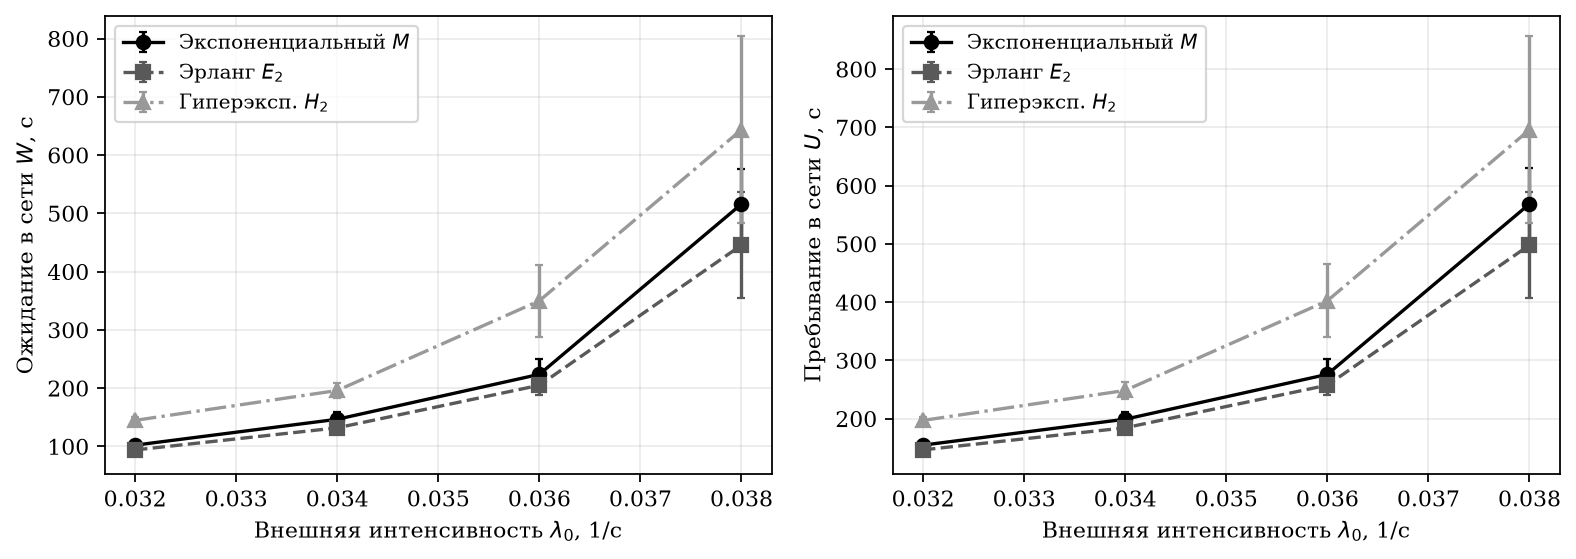

In [21]:
open_results = pd.read_csv(RESULTS/"open.csv")
display(open_results[open_results.comparison=="matched"][["law","arrival","lambda_","through","w","u","u_ci"]])
actual_lambda = open_results[(open_results.law=="M")&(open_results.comparison=="matched")&(open_results.arrival=="M")].lambda_.iloc[0]
exact_open = open_exact(actual_lambda)
print("Точный M-случай при заданной интенсивности GPSS: W =", exact_open["w"], "; U =", exact_open["u"])
display(Image(filename=str(ROOT/"report-source"/"figures"/"open.png")))

## 18. Распределения и выводы сетевой части

Производительность закрытой сети насыщается, а $U=M/\lambda_0$ дальше растёт почти линейно. У открытой сети при приближении к $\lambda_{0,\text{пред}}$ времена резко возрастают. Например, у экспоненциального У3

$$\rho_3=25\lambda_0,\qquad u_3=\frac{10}{1-\rho_3}.$$

Детерминированный внешний поток уменьшает разброс поступлений и очереди при той же средней интенсивности. Изменение закона У3 в закрытой сети может менять производительность. В устойчивой открытой сети долговременный выход равен внешнему входу, поэтому закон обслуживания отражается прежде всего на очередях и временах.

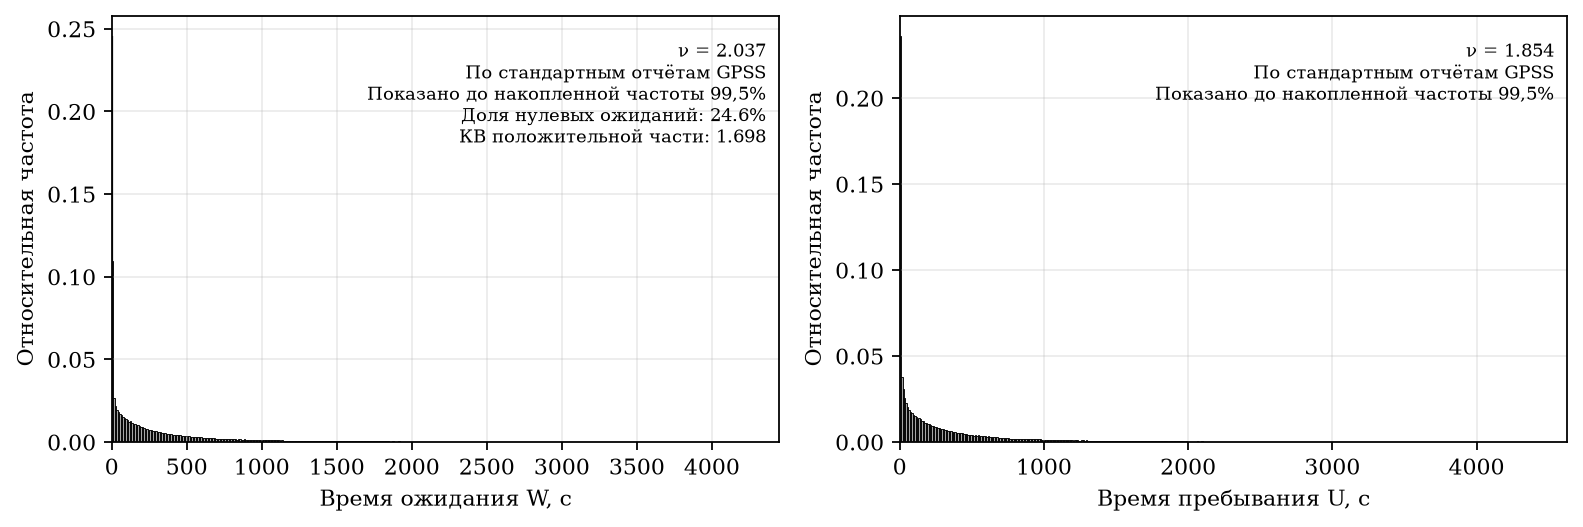

In [22]:
display(Image(filename=str(ROOT/"report-source"/"figures"/"hist_network.png")))

### Формы 2 и 3 сетевой части

Экспоненциальная и неэкспоненциальная сети показаны рядом по образцу методички. Узловое время относится к одному посещению узла, сетевое — ко всему циклу, включая повторные посещения. Общая загрузка сети не усредняется вместо узловых загрузок.

In [23]:
protocols = pd.read_csv(RESULTS/"network_protocols.csv")
for kind in ["closed","open"]:
    source = closed_results[closed_results.M==3] if kind=="closed" else open_results[
        (open_results.comparison=="matched")&(open_results.arrival=="M")]
    keys = ["rho","l","through","w","u"] if kind=="closed" else ["rho","l","m","w","u"]
    labels = {"rho":"Загрузка", "l":"Длина очереди", "m":"Число заявок в системе",
              "through":"Производительность", "w":"Время ожидания", "u":"Время пребывания"}
    tables = {}
    for law in ["M","E2","H2"]:
        row = source[source.law==law].iloc[0]
        tables[law] = pd.DataFrame({node:[row[k+str(j)] if j else
            (np.nan if k=="rho" else row[k]) for k in keys]
            for j,node in [(1,"У1"),(2,"У2"),(3,"У3"),(0,"Сеть")]},
            index=[labels[k] for k in keys])
    for law in ["E2","H2"]:
        display(Markdown(f"**Форма {'2 — ЗСеМО' if kind=='closed' else '3 — РСеМО'}: M и {law} в У3.**"))
        display(pd.concat({"Экспоненциальная":tables["M"],"Неэкспоненциальная":tables[law]},axis=1))
display(protocols.groupby(["kind","law"]).agg(
    duration_mean=("duration","mean"), duration_min=("duration","min"),
    duration_max=("duration","max"), cycles_per_run=("cycles","first")))

**Форма 2 — ЗСеМО: M и E2 в У3.**

Экспоненциальная                                \
                                 У1        У2        У3      Сеть   
Загрузка                   0.183625  0.206250  0.918125       NaN   
Длина очереди              0.030875  0.000000  1.042875  1.073750   
Производительность         0.183592  0.055028  0.091847  0.036717   
Время ожидания             0.167875  0.000000 11.354875 29.245125   
Время пребывания           1.167375 14.989375 21.349750 81.711750   

                   Неэкспоненциальная                                
                                   У1        У2        У3      Сеть  
Загрузка                     0.186125  0.209250  0.930625       NaN  
Длина очереди                0.022625  0.000000  1.024000  1.046625  
Производительность           0.186185  0.055806  0.093144  0.037235  
Время ожидания               0.121500  0.000000 10.995375 28.113250  
Время пребывания             1.121000 14.989250 20.987375 80.573250

**Форма 2 — ЗСеМО: M и H2 в У3.**

Экспоненциальная                                \
                                 У1        У2        У3      Сеть   
Загрузка                   0.183625  0.206250  0.918125       NaN   
Длина очереди              0.030875  0.000000  1.042875  1.073750   
Производительность         0.183592  0.055028  0.091847  0.036717   
Время ожидания             0.167875  0.000000 11.354875 29.245125   
Время пребывания           1.167375 14.989375 21.349750 81.711750   

                   Неэкспоненциальная                                
                                   У1        У2        У3      Сеть  
Загрузка                     0.177750  0.199750  0.891375       NaN  
Длина очереди                0.037875  0.000000  1.094500  1.132375  
Производительность           0.177796  0.053297  0.088961  0.035539  
Время ожидания               0.213000  0.000000 12.303125 31.863000  
Время пребывания             1.212500 14.984250 22.323625 84.420500

**Форма 3 — РСеМО: M и E2 в У3.**

Экспоненциальная                                  \
                                     У1        У2         У3       Сеть   
Загрузка                       0.182625  0.205000   0.916250        NaN   
Длина очереди                  0.040625  0.002875   9.891125   9.934625   
Число заявок в системе         0.223250  0.822750  10.807375  11.853375   
Время ожидания                 0.222500  0.048250 108.018125 270.503000   
Время пребывания               1.221750 15.021875 118.032125 322.814500   

                       Неэкспоненциальная                                  
                                       У1        У2         У3       Сеть  
Загрузка                         0.186375  0.209500   0.932750        NaN  
Длина очереди                    0.033000  0.001875  11.710125  11.745000  
Число заявок в системе           0.219375  0.840000  12.642875  13.702250  
Время ожидания                   0.176750  0.034875 125.325750 315.071375  
Время пребывания                 1.175875 15.001250 135.331875 367.644500

**Форма 3 — РСеМО: M и H2 в У3.**

Экспоненциальная                                  \
                                     У1        У2         У3       Сеть   
Загрузка                       0.182625  0.205000   0.916250        NaN   
Длина очереди                  0.040625  0.002875   9.891125   9.934625   
Число заявок в системе         0.223250  0.822750  10.807375  11.853375   
Время ожидания                 0.222500  0.048250 108.018125 270.503000   
Время пребывания               1.221750 15.021875 118.032125 322.814500   

                       Неэкспоненциальная                                  
                                       У1        У2         У3       Сеть  
Загрузка                         0.177750  0.199625   0.892375        NaN  
Длина очереди                    0.050125  0.005250  10.702625  10.758000  
Число заявок в системе           0.227875  0.803750  11.595000  12.626625  
Время ожидания                   0.282125  0.098875 120.210750 302.367125  
Время пребывания                 1.281000 15.065000 130.232125 354.851250

duration_mean   duration_min   duration_max  cycles_per_run
kind   law                                                             
closed E2   805730.223875  792530.713000  814473.401000           30000
       H2   844234.357750  831275.558000  854646.025000           30000
       M    817108.895750  805478.933000  825807.364000           30000
open   E2  1074827.146500 1068803.068000 1086522.123000           40000
       H2  1123416.846875 1116321.541000 1131954.762000           40000
       M   1090901.072875 1084003.005000 1097966.177000           40000

## 19. Модели GPSS и повторение эксперимента на защите

Тексты находятся в папке `gpss`. В GPSS World создаётся новый объект Model, в него вставляется нужный `.txt`, затем выполняется Create Simulation. Команды разгона и измерений уже включены. Для интерактивного показа удали последнюю строку `EXIT 1`.

`QUEUE`/`DEPART` измеряют очередь, `ENTER`/`LEAVE` занимают и освобождают приборы, `ADVANCE` задаёт обслуживание, `TRANSFER` выбирает маршрут, `TABLE`/`TABULATE` собирают распределения.

Трансляция и выполнение моделей подтверждены сохранёнными стандартными отчётами GPSS. Предлагаемая нагрузка и фактическая загрузка исследованы отдельными сериями. Полные проекты с командами независимых повторений — в `gpss-native/series`.

In [24]:
models = sorted((ROOT/"gpss").glob("*.txt"))
print("Подготовлено текстов GPSS:", len(models))
print((ROOT/"gpss"/"smo_baseline.txt").read_text())

Подготовлено текстов GPSS: 495
* UIR3, variant 16/6/6. baseline
* K is the number of servers; E is WAITING capacity.
* Local routing 0.30 / 0.45 / 0.25; no rerouting after rejection.
        INITIAL X$TI,1
TW      TABLE P2,0,1,300
TU      TABLE P3,0,1,300
NODE1   STORAGE 1
NODE2   STORAGE 1
NODE3   STORAGE 1
        GENERATE ,,,1
SOURCE  ADVANCE (Exponential(1,0,1.25))
EMIT    SPLIT 1,ARRIVE
        SAVEVALUE TI+,1
        TEST LE X$TI,300,REWIND
        TRANSFER ,SOURCE
REWIND  SAVEVALUE TI,1
        TRANSFER ,SOURCE
ARRIVE  SAVEVALUE ARRIVED+,1
        ASSIGN 1,AC1
        TRANSFER .30,ROUTE23,IN1
ROUTE23 TRANSFER 0.642857142857,IN3,IN2
IN1     TEST L (S$NODE1+Q$BUF1),3,LOSS
        QUEUE BUF1
        ENTER NODE1
        DEPART BUF1
        ASSIGN 2,(AC1-P1)
        TABULATE TW
        ADVANCE (Exponential(3,0,5))
        LEAVE NODE1
        ASSIGN 3,(AC1-P1)
        TABULATE TU
        SAVEVALUE DONE+,1
        TERMINATE 1
IN2     TEST L (S$NODE2+Q$BUF2),2,LOSS
        QUEUE BUF2
  

Полные тексты шести сетевых моделей — замкнутой и разомкнутой с $M$, $E_2$ и $H_2$ в У3 — включены в приложения PDF. В папке `gpss` также есть варианты переходного режима для обеих способов изменения нагрузки.

## 20. Пересчёт контрольной модели Python
Следующая ячейка по умолчанию только показывает команду. Если изменить флаг на True, пересчитываются вспомогательные опыты Python. Основные данные GPSS при этом не заменяются. Для обновления основных результатов запусти проекты в GPSS и повтори обработку стандартных отчётов.

In [25]:
RUN_FULL_SERIES = False
if RUN_FULL_SERIES:
    from experiments import run_all
    from methodical_tables import main as rebuild_methodical_tables
    run_all()
    rebuild_methodical_tables()
    make_figures()
else:
    print("Полная серия: python experiments.py; затем python methodical_tables.py")

Полная серия: python experiments.py; затем python methodical_tables.py
